In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(rc={'figure.figsize':(11.7,8.27), "figure.dpi": 200})
%matplotlib inline

In [2]:
# PATHS
out_dir = '/fh/fast/ha_g/user/yhuang2/triton_cnn/scripts/TritonCNN/version6_onehead_fpkmlabel/'
images_file = out_dir + 'activity_images.npy'
scalars_file = out_dir + 'activity_scalars.npy'
labels_file = out_dir + 'activity_labels.npy'
idents_file = out_dir + 'activity_identifiers.npy'
labels_ref = '/fh/fast/ha_g/user/yhuang2/triton_cnn/references/LuCaP_activity_differential_analysis_fpkm_limma.csv'

In [3]:
triton_results = '/fh/fast/ha_g/user/rpatton/LuCaP_data/Triton_TSS/results/'

# Scalars

In [100]:
metadata = pd.read_csv(os.path.join(triton_results, "TritonCompositeFM.tsv"), sep = "\t")

In [101]:
pivoted_df = metadata.pivot_table(index=["sample", "site"],
                                  columns="feature",
                                  values="value")

In [102]:
metadata_proc = pivoted_df.reset_index()
metadata_proc.head(10)

feature,sample,site,central-depth,central-diversity,central-loc,fragment-diversity,fragment-entropy,fragment-mad,fragment-mean,fragment-median,fragment-ratio,fragment-stdev,mean-depth,minus-one-pos,np-amplitude,np-period,np-score,plus-minus-ratio,plus-one-pos,var-ratio
0,136CR_LuCaP,A1BG,0.488743,1.032518,33.0,0.154334,0.482243,19.0,134.365751,136.0,2.814516,44.794757,26.765956,-123.0,0.531525,179.222222,0.630539,0.749275,78.0,0.787868
1,136CR_LuCaP,A1CF,1.928527,NaN,37.0,0.227723,0.517033,17.0,140.207921,138.0,2.607143,46.471074,24.664911,-239.0,0.655412,161.181818,1.158978,1.954085,197.0,0.949303
2,136CR_LuCaP,A2M,0.798933,0.949838,22.0,0.189759,0.493521,18.0,137.620482,138.0,2.353535,40.011903,34.715385,-147.0,0.540486,190.400000,0.997884,0.930117,108.0,0.764468
3,136CR_LuCaP,A2ML1,1.315919,0.930980,-1.0,0.177322,0.497770,19.0,138.758745,135.0,2.635965,50.507554,34.730551,-52.0,0.625383,187.000000,2.357943,1.133898,80.0,0.878157
4,136CR_LuCaP,A3GALT2,1.247113,1.018400,-39.0,0.158730,0.481250,18.0,136.734694,137.0,2.528000,46.246700,27.298953,-214.0,0.790337,185.300000,1.732350,0.905797,256.0,0.860763
5,136CR_LuCaP,A4GALT,8.648272,NaN,55.0,0.240076,0.544106,23.0,130.669187,132.0,2.725352,51.841023,27.702012,-196.0,1.347496,155.545455,1.647845,0.752034,178.0,1.051695
6,136CR_LuCaP,A4GNT,0.770315,1.072770,-46.0,0.134429,0.462981,18.0,138.760155,139.0,1.988439,44.994654,47.757779,-131.0,0.614001,199.333333,2.451724,1.116048,118.0,0.872782
7,136CR_LuCaP,AAAS,1.624921,0.999909,13.0,0.180284,0.520054,27.0,142.420959,135.0,2.145251,65.052066,40.240348,-305.0,0.721157,200.555556,1.244125,0.636023,183.0,0.832618
8,136CR_LuCaP,AACS,0.008165,1.024226,-13.0,0.198571,0.518572,22.0,130.257143,130.0,3.729730,56.958001,24.013682,-200.0,0.984177,187.888889,2.488518,1.233796,118.0,0.996677
9,136CR_LuCaP,AADAC,0.667427,NaN,-67.0,0.235160,0.517319,18.0,133.264840,135.0,3.055556,39.701089,21.226549,-143.0,0.749332,195.142857,2.995796,0.589336,135.0,0.991316


In [109]:
metadata_proc.loc[metadata_proc["sample"] == "136CR_LuCaP"].drop(columns=["sample"]).set_index("site")

feature,central-depth,central-diversity,central-loc,fragment-diversity,fragment-entropy,fragment-mad,fragment-mean,fragment-median,fragment-ratio,fragment-stdev,mean-depth,minus-one-pos,np-amplitude,np-period,np-score,plus-minus-ratio,plus-one-pos,var-ratio
site,,,,,,,,,,,,,,,,,,
A1BG,0.488743,1.032518,33.0,0.154334,0.482243,19.0,134.365751,136.0,2.814516,44.794757,26.765956,-123.0,0.531525,179.222222,0.630539,0.749275,78.0,0.787868
A1CF,1.928527,NaN,37.0,0.227723,0.517033,17.0,140.207921,138.0,2.607143,46.471074,24.664911,-239.0,0.655412,161.181818,1.158978,1.954085,197.0,0.949303
A2M,0.798933,0.949838,22.0,0.189759,0.493521,18.0,137.620482,138.0,2.353535,40.011903,34.715385,-147.0,0.540486,190.400000,0.997884,0.930117,108.0,0.764468
A2ML1,1.315919,0.930980,-1.0,0.177322,0.497770,19.0,138.758745,135.0,2.635965,50.507554,34.730551,-52.0,0.625383,187.000000,2.357943,1.133898,80.0,0.878157
A3GALT2,1.247113,1.018400,-39.0,0.158730,0.481250,18.0,136.734694,137.0,2.528000,46.246700,27.298953,-214.0,0.790337,185.300000,1.732350,0.905797,256.0,0.860763
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZYG11A,0.780537,1.006349,3.0,0.188702,0.513036,23.0,132.295673,131.0,2.887850,57.039979,34.137610,-96.0,0.608372,189.400000,1.603497,1.068592,91.0,0.766220
ZYG11B,1.083363,1.059560,63.0,0.180291,0.512539,25.0,127.509518,129.0,3.420792,51.763429,33.537186,-289.0,0.773130,168.700000,1.532629,0.716513,165.0,1.011384
ZYX,-0.064455,1.112974,20.0,0.169078,0.511285,26.0,132.553345,130.0,3.007246,68.353494,37.463262,-250.0,0.692341,191.444444,1.128485,0.531160,147.0,1.032894


In [104]:
for s in list(metadata_proc["sample"].unique()):
    filtered_for_sample = metadata_proc.loc[metadata_proc["sample"] == s].drop(columns=["sample"]).set_index("site")

['136CR_LuCaP',
 '136_LuCaP',
 '141_LuCaP',
 '145-1_LuCaP',
 '145-2_LuCaP',
 '145P_LuCaP',
 '147P_LuCaP',
 '167P1_LuCaP',
 '167P2_LuCaP',
 '170-2_LuCaP',
 '170.3_LuCaP',
 '173-1_LuCaP',
 '174-1_LuCaP',
 '176CR_LuCaP',
 '176_LuCaP',
 '189-3_LuCaP',
 '189-4_LuCaP',
 '208-4_LuCaP',
 '23-1_LuCaP',
 '235-3_LuCaP',
 '35CR_LuCaP',
 '35_LuCaP',
 '49_LuCaP',
 '58_LuCaP',
 '70CR_LuCaP',
 '70_LuCaP',
 '77CR_LuCaP',
 '78_LuCaP',
 '81_LuCaP',
 '86-2CR_LuCaP',
 '92_LuCaP',
 '93_LuCaP',
 '96P_LuCaP',
 '96_LuCaP']

In [13]:
print("Variables:")
for v in metadata_proc.columns.to_list():
    print(f"{v}")

Variables:
sample
site
central-depth
central-diversity
central-loc
fragment-diversity
fragment-entropy
fragment-mad
fragment-mean
fragment-median
fragment-ratio
fragment-stdev
mean-depth
minus-one-pos
np-amplitude
np-period
np-score
plus-minus-ratio
plus-one-pos
var-ratio


In [127]:
PLOT_OUTPUT = '/fh/scratch/delete90/ha_g/users/anair3/repositories/cfDNA-gene-exp-inference/analysis/plots'

In [128]:
# The following plot helps visualize if distributions of covariates are similar across samples
# This is important in detecting abnormalities in samples and avoiding sample bias in further analysis
def plot_distribution_across_samples(metadata, variable_name, filters = []):
    grouped_metadata_proc = metadata_proc.groupby('sample')
    plt.figure(figsize = (15, 10))
    for sample, data in grouped_metadata_proc:
        if len(filters) == 0:
            plt.hist(data[variable_name].dropna(), bins=500, histtype='step', label=sample)
        if sample in filters:
            plt.hist(data[variable_name].dropna(), bins=500, histtype='step', label=sample)
    plt.title(variable_name)
    plt.legend()
    plt.savefig(os.path.join(PLOT_OUTPUT, f"{variable_name}.pdf"))
    plt.clf()

In [129]:
metadata_proc['sample'].unique()

array(['136CR_LuCaP', '136_LuCaP', '141_LuCaP', '145-1_LuCaP',
       '145-2_LuCaP', '145P_LuCaP', '147P_LuCaP', '167P1_LuCaP',
       '167P2_LuCaP', '170-2_LuCaP', '170.3_LuCaP', '173-1_LuCaP',
       '174-1_LuCaP', '176CR_LuCaP', '176_LuCaP', '189-3_LuCaP',
       '189-4_LuCaP', '208-4_LuCaP', '23-1_LuCaP', '235-3_LuCaP',
       '35CR_LuCaP', '35_LuCaP', '49_LuCaP', '58_LuCaP', '70CR_LuCaP',
       '70_LuCaP', '77CR_LuCaP', '78_LuCaP', '81_LuCaP', '86-2CR_LuCaP',
       '92_LuCaP', '93_LuCaP', '96P_LuCaP', '96_LuCaP'], dtype=object)

In [130]:
vars_to_plot = list(set(metadata_proc.columns.to_list()) - set(['site', 'sample']))
vars_to_plot

['fragment-diversity',
 'fragment-mad',
 'fragment-median',
 'central-diversity',
 'var-ratio',
 'minus-one-pos',
 'np-score',
 'mean-depth',
 'plus-one-pos',
 'np-amplitude',
 'fragment-stdev',
 'np-period',
 'central-depth',
 'fragment-entropy',
 'fragment-mean',
 'plus-minus-ratio',
 'fragment-ratio',
 'central-loc']

In [131]:
for variable_name in vars_to_plot: 
    plot_distribution_across_samples(metadata_proc, variable_name, filters = ['176CR_LuCaP', '86-2CR_LuCaP', '173-1_LuCaP', '81_LuCaP'])

<Figure size 3000x2000 with 0 Axes>

<Figure size 3000x2000 with 0 Axes>

<Figure size 3000x2000 with 0 Axes>

<Figure size 3000x2000 with 0 Axes>

<Figure size 3000x2000 with 0 Axes>

<Figure size 3000x2000 with 0 Axes>

... (8 outputs left out)

<Figure size 3000x2000 with 0 Axes>

<Figure size 3000x2000 with 0 Axes>

<Figure size 3000x2000 with 0 Axes>

<Figure size 3000x2000 with 0 Axes>

# Images

In [63]:
example_image = np.load(os.path.join(triton_results,"96P_LuCaP_TritonProfiles.npz"))

In [64]:
def clean_input(input_object, identifier):
    out_dict = {}
    print('Cleaning sample ' + identifier + ': ' +
          str(len(input_object.items())) + ' initial profiles.')
    for key, signals in input_object.items():
        if signals.shape == (11, 2000):  # functional input matrix
            signals = signals.T  # functional input matrix
            if np.mean(signals[:, 0]) > 10:  # at least 10x depth in the profile
                # normalize to mean = 1 all signals, excluding peak locs and nucleotide freqs
                for col in range(7):
                    signals[:, col] = scale_arr(signals[:, col])
                if not np.isnan(signals).any():
                    out_dict[identifier + '_' + key] = signals
    print(' -> ' + str(len(out_dict)) + ' profiles met clean-up criteria.')
    return out_dict
def scale_arr(input_array):
    # normalize:
    # mean_val = np.nanmean(input_array)
    # input_array = input_array / mean_val
    # standardize:
    mean_val, std_val = np.nanmean(input_array), np.nanstd(input_array)
    if std_val != 0:
        #     input_array = (input_array - mean_val)/std_val
        # the 3 is to capture the 99.7 rule at +/- 1
        input_array = (input_array - mean_val) / (3 * std_val)
        input_array[input_array > 1] = 1
        input_array[input_array < -1] = -1
        # input_array = input_array.apply(lambda x: x / np.linalg.norm(x))
    else:
        input_array = np.nan
    return input_array

In [65]:
image_proc = clean_input(example_image, "test")
image_proc

Cleaning sample test: 19337 initial profiles.


/app/software/SciPy-bundle/2021.10-foss-2021b/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe')
/loc/scratch/23697989/ipykernel_34961/2004296768.py:25: RuntimeWarning: invalid value encountered in subtract
  input_array = (input_array - mean_val) / (3 * std_val)


 -> 765 profiles met clean-up criteria.


{'test_C7orf33': array([[ 0.58856342,  0.33678975,  0.2419865 , ...,  0.        ,
          0.        ,  0.        ],
        [ 0.58856342,  0.34203699,  0.24657807, ...,  0.        ,
          0.        ,  0.        ],
        [ 0.58856342,  0.34687578,  0.25103608, ...,  0.        ,
          0.        ,  0.        ],
        ...,
        [-0.15020479, -0.38427707, -0.33298004, ...,  0.        ,
          0.        ,  0.        ],
        [-0.15020479, -0.37848549, -0.32689016, ...,  0.        ,
          1.        ,  0.        ],
        [-0.09327654, -0.33668574, -0.32085019, ...,  0.        ,
          0.        ,  0.        ]]),
 'test_AOC1': array([[ 0.50750423,  0.07476039,  0.03851192, ...,  0.        ,
          0.        ,  1.        ],
        [ 0.50750423,  0.0682233 ,  0.04038935, ...,  0.        ,
          0.        ,  1.        ],
        [ 0.50750423,  0.06175813,  0.04242124, ...,  0.        ,
          1.        ,  0.        ],
        ...,
        [-0.27406417, -0.

In [66]:
image_vars = ["depth", "probable-nucleosome-center-profile", "phased-nucleosome-profile", "fragment-short-long-ratio", "fragment-diversity", \
              "fragment-entropy", "peak-location", "A-freq", "C-freq", "G-freq", "T-freq"]
for k in image_proc:
    df=pd.DataFrame(image_proc[k])
    df=df.T
    df.index= image_vars
    image_proc[k]=image_vars

In [79]:
samples = []
for p in os.listdir(triton_results):
    s = p.split("_LuCaP_TritonProfiles.npz")
    if len(s)==2:
        samples.append("LuCaP_"+s[0])
print(samples)

['LuCaP_70CR', 'LuCaP_208-4', 'LuCaP_145-2', 'LuCaP_189-3', 'LuCaP_167P2', 'LuCaP_167P1', 'LuCaP_86-2', 'LuCaP_145-1', 'LuCaP_86-2CR', 'LuCaP_189-4', 'LuCaP_81', 'LuCaP_235-3', 'LuCaP_147P', 'LuCaP_23-1', 'LuCaP_92', 'LuCaP_77CR', 'LuCaP_145P', 'LuCaP_136', 'LuCaP_173-1', 'LuCaP_96', 'LuCaP_49', 'LuCaP_58', 'LuCaP_77', 'LuCaP_136CR', 'LuCaP_170-2', 'LuCaP_35CR', 'LuCaP_93', 'LuCaP_170.3', 'LuCaP_70', 'LuCaP_174-1', 'LuCaP_96P', 'LuCaP_141', 'LuCaP_176', 'LuCaP_35', 'LuCaP_78', 'LuCaP_176CR']


In [81]:
from sklearn.model_selection import train_test_split

In [82]:
train_test_split(samples, train_size=0.9)

[['LuCaP_173-1',
  'LuCaP_77CR',
  'LuCaP_96P',
  'LuCaP_167P1',
  'LuCaP_235-3',
  'LuCaP_81',
  'LuCaP_170-2',
  'LuCaP_136',
  'LuCaP_174-1',
  'LuCaP_70CR',
  'LuCaP_208-4',
  'LuCaP_93',
  'LuCaP_92',
  'LuCaP_176',
  'LuCaP_145P',
  'LuCaP_70',
  'LuCaP_167P2',
  'LuCaP_35CR',
  'LuCaP_147P',
  'LuCaP_176CR',
  'LuCaP_77',
  'LuCaP_136CR',
  'LuCaP_145-2',
  'LuCaP_49',
  'LuCaP_96',
  'LuCaP_23-1',
  'LuCaP_86-2CR',
  'LuCaP_35',
  'LuCaP_189-3',
  'LuCaP_145-1',
  'LuCaP_86-2',
  'LuCaP_141'],
 ['LuCaP_170.3', 'LuCaP_189-4', 'LuCaP_78', 'LuCaP_58']]

In [ ]:
def image_for_sample()

In [60]:
image_vars = ["depth", "probable-nucleosome-center-profile", "phased-nucleosome-profile", "fragment-short-long-ratio", "fragment-diversity", \
              "fragment-entropy", "peak-location", "A-freq", "C-freq", "G-freq", "T-freq"]

# 1-depth (GC-corrected, if provided)  
# 2-probable nucleosome center profile (fragment length re-weighted depth)  
# 3-phased-nucleosome profile (Fourier filtered probable nucleosome center profile)  
# 4-fragment lengths' short:long ratio (x <= 150 / x > 150)  
# 5-fragment lengths' diversity (unique fragment lengths / total fragments, i.e. multiset support / cardinality)  
# 6-fragment lengths' Shannon Entropy (normalized to window Shannon Entropy)  
# 7-peak locations (-1: trough, 1: peak, -2: minus-one peak, 2: plus-one peak, 3: inflection point)***  
# 8-A (Adenine) frequency**  
# 9-C (Cytosine) frequency**  
# 10-G (Guanine) frequency**  
# 11-T (Tyrosine) frequency**  

In [61]:
image_proc_T = image_proc['test_C7orf33'].T

In [62]:
image_proc_T.index= image_vars
image_proc_T

,0,1,2,3,4,5,6,7,8,9,...,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999
depth,0.588563,0.588563,0.588563,0.588563,0.588563,0.588563,0.588563,0.588563,0.588563,0.518648,...,-0.149192,-0.149192,-0.149192,-0.149192,-0.149192,-0.205824,-0.205824,-0.150205,-0.150205,-0.093277
probable-nucleosome-center-profile,0.336790,0.342037,0.346876,0.351285,0.355244,0.358735,0.361742,0.364252,0.366252,0.367735,...,-0.421386,-0.416485,-0.411445,-0.406268,-0.400958,-0.395519,-0.389957,-0.384277,-0.378485,-0.336686
phased-nucleosome-profile,0.241987,0.246578,0.251036,0.255359,0.259545,0.263593,0.267501,0.271269,0.274894,0.278376,...,-0.376790,-0.370424,-0.364090,-0.357789,-0.351524,-0.345300,-0.339117,-0.332980,-0.326890,-0.320850
fragment-short-long-ratio,0.027099,0.027099,0.027099,0.027099,0.027099,0.027099,0.027099,0.027099,0.027099,-0.000539,...,0.340335,0.340335,0.340335,0.340335,0.340335,0.266632,0.266632,0.340335,0.340335,0.137653
fragment-diversity,0.006089,0.006089,0.006089,0.006089,0.006089,0.006089,0.006089,0.006089,0.006089,-0.011043,...,-0.361018,-0.361018,-0.361018,-0.361018,-0.361018,-0.422203,-0.422203,-0.361018,-0.361018,-0.307992
fragment-entropy,-0.051993,-0.051993,-0.051993,-0.051993,-0.051993,-0.051993,-0.051993,-0.051993,-0.051993,-0.032297,...,-0.377979,-0.377979,-0.377979,-0.377979,-0.377979,-0.520840,-0.520840,-0.377979,-0.377979,-0.256123
peak-location,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A-freq,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
C-freq,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
G-freq,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000


In [31]:
pd.DataFrame.from_dict(image_proc, orient='index')

ValueError: Must pass 2-d input. shape=(765, 2000, 11)

In [30]:
np.array(image_proc).flatten(0)

TypeError: order must be str, not int

# Labels

In [83]:
labels_ref = '/fh/fast/ha_g/user/yhuang2/triton_cnn/references/LuCaP_activity_differential_analysis_fpkm_limma.csv'

In [94]:
labels = pd.read_csv(labels_ref)
labels

,Unnamed: 0,105,105CR,136,136CR,136CR2,141,145-1,145-2,147,...,78,78CR,81,81CR,86-2,86-2CR,92,93,96,96CR
0,A1BG,2,1,0,0,0,1,1,1,2,...,0,0,1,0,0,0,1,1,0,2
1,A2M,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,A2MP1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,NAT1,1,1,2,2,2,1,1,1,2,...,2,1,1,1,2,2,0,1,1,1
4,NAT2,0,1,0,0,0,0,0,0,0,...,0,0,0,0,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27358,ZNF71-SMIM17,1,1,1,0,0,0,1,1,0,...,0,0,0,1,1,1,1,1,1,0
27359,LOC114841035,2,2,2,1,1,2,1,1,2,...,1,1,1,1,1,1,2,1,2,2
27360,GUCA1ANB,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
27361,TNRC6B-DT,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [92]:
labels.iloc[:, 1:]

,105,105CR,136,136CR,136CR2,141,145-1,145-2,147,147CR,...,78,78CR,81,81CR,86-2,86-2CR,92,93,96,96CR
0,2,1,0,0,0,1,1,1,2,1,...,0,0,1,0,0,0,1,1,0,2
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,1,2,2,2,1,1,1,2,2,...,2,1,1,1,2,2,0,1,1,1
4,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27358,1,1,1,0,0,0,1,1,0,1,...,0,0,0,1,1,1,1,1,1,0
27359,2,2,2,1,1,2,1,1,2,2,...,1,1,1,1,1,1,2,1,2,2
27360,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
27361,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [91]:
np.array(labels.iloc[:, 1:])

array([[2, 1, 0, ..., 1, 0, 2],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

<AxesSubplot:>

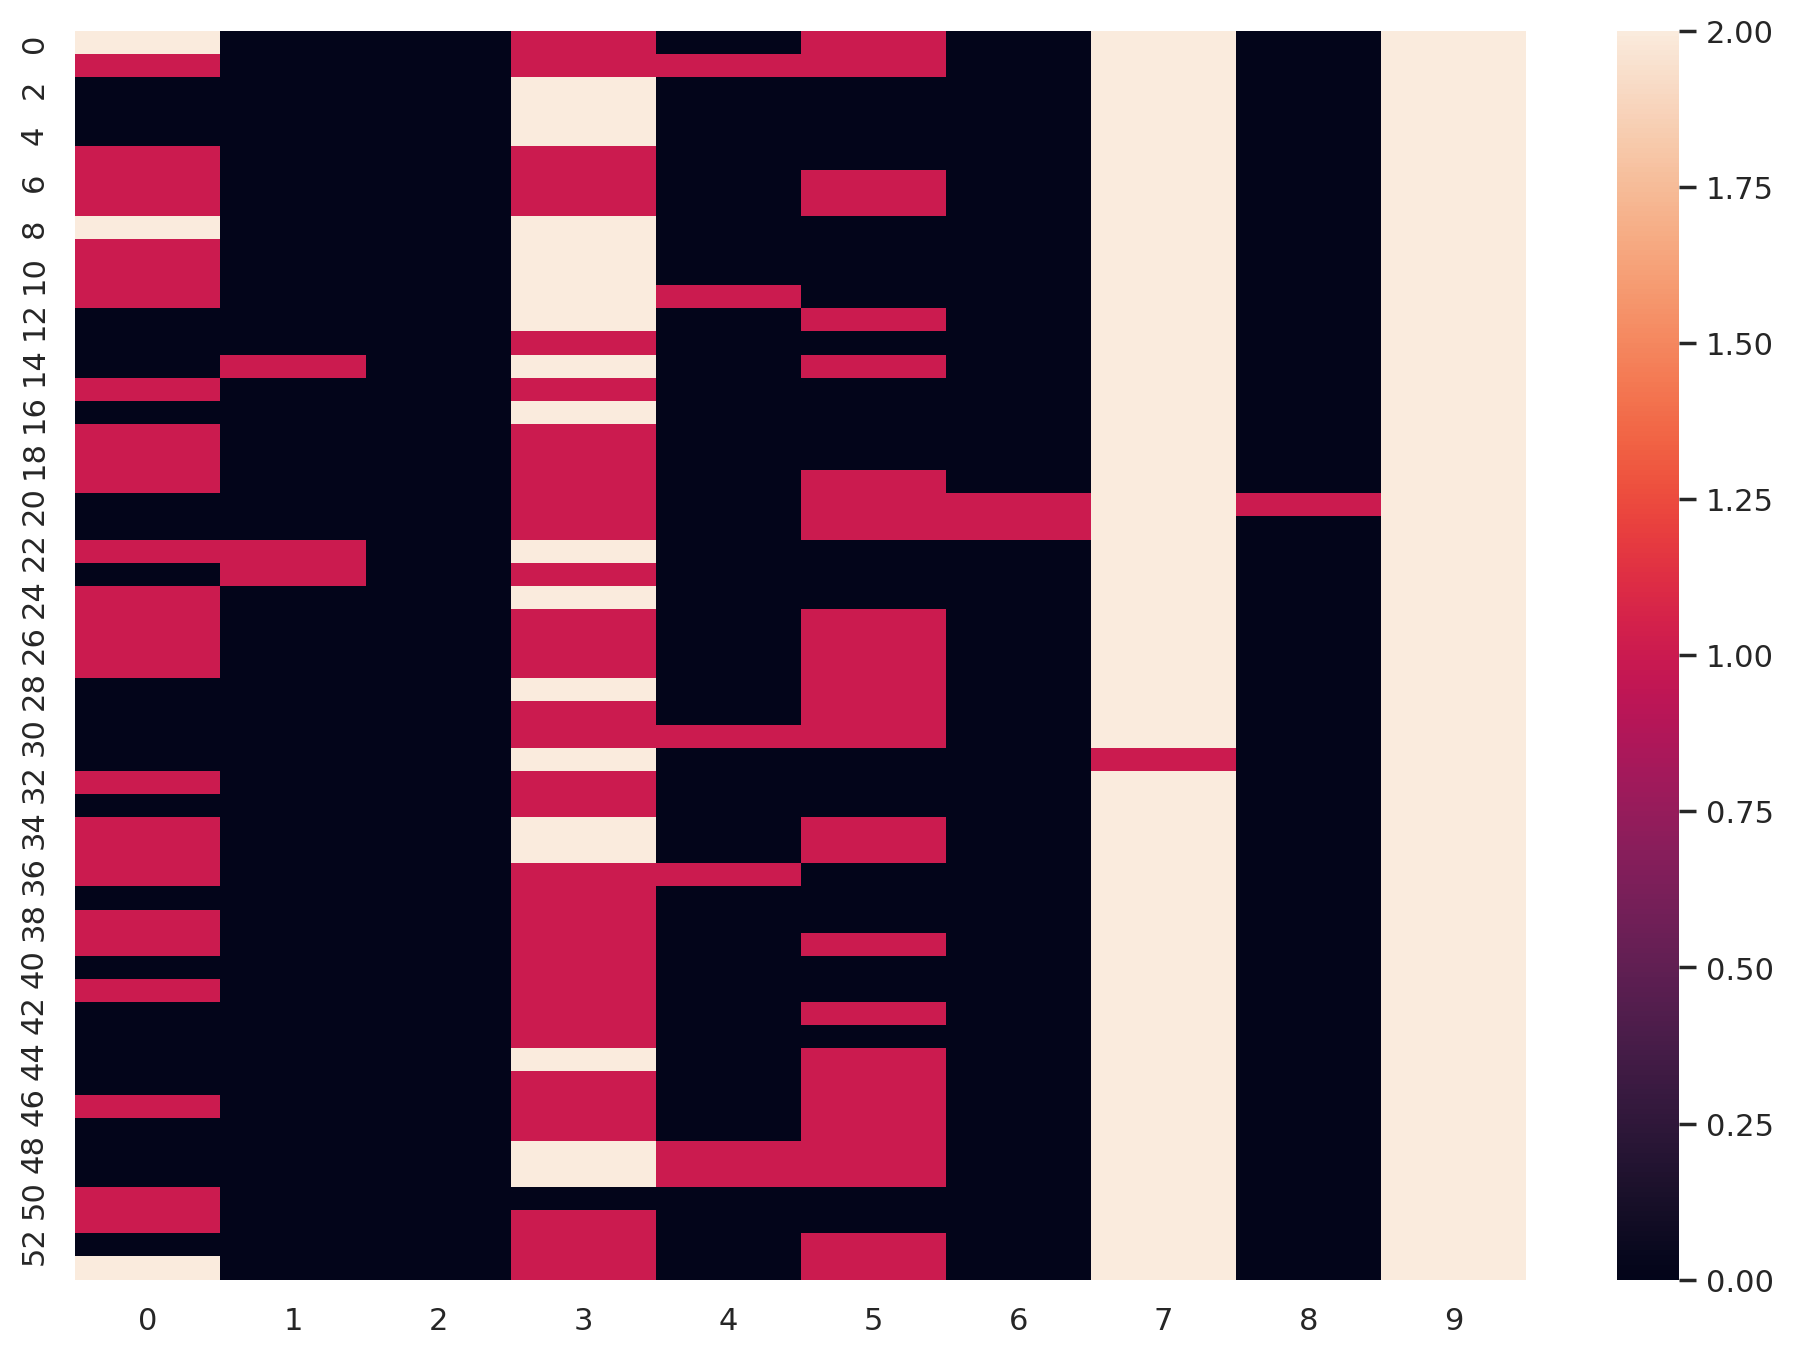

In [99]:
sns.set(rc={'figure.figsize':(11.7,8.27), "figure.dpi": 200})
sns.heatmap(np.array(labels.iloc[:10, 1:]).T)

# Wavelet transform

In [35]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(rc={'figure.figsize':(11.7,8.27), "figure.dpi": 200})
%matplotlib inline

In [16]:
training_path = '/fh/scratch/delete90/ha_g/users/anair3/repositories/cfDNA-gene-exp-inference/data/training_small.npz'

In [17]:
training_data = np.load(training_path)

In [18]:
len(training_data["labels"])

34054

In [12]:
images = training_data["images"]

In [14]:
i = images[0]
i

array([[ 0.74699795,  0.5838209 ,  0.49757516, ...,  0.        ,
         0.        ,  1.        ],
       [ 0.74699795,  0.5860876 ,  0.50187814, ...,  0.        ,
         0.        ,  1.        ],
       [ 0.74699795,  0.5880135 ,  0.5062574 , ...,  0.        ,
         0.        ,  1.        ],
       ...,
       [ 0.10059357, -0.13486753, -0.02002843, ...,  0.        ,
         0.        ,  1.        ],
       [ 0.10059357, -0.1277718 , -0.01081715, ...,  0.        ,
         0.        ,  0.        ],
       [ 0.10059357, -0.120302  , -0.00170309, ...,  1.        ,
         0.        ,  0.        ]], dtype=float32)

In [54]:
imaging_names = ["1. Depth", "2. Probable Nucleosome Center Profile", "3. Phased Nucleosome Profile", \
                 "4. Fragment Length Short:Long ratio", "5. Fragment Length Diversity", "6. Fragement Length Entropy", \
                "7. Peaks", "8. A-Adenine", "9. C-Cytosine", "10. G-Guanine", "11. T-Tyrosine"]
"""
1-depth (GC-corrected, if provided)  
2-probable nucleosome center profile (fragment length re-weighted depth)  
3-phased-nucleosome profile (Fourier filtered probable nucleosome center profile)  
4-fragment lengths' short:long ratio (x <= 150 / x > 150)  
5-fragment lengths' diversity (unique fragment lengths / total fragments, i.e. multiset support / cardinality)  
6-fragment lengths' Shannon Entropy (normalized to window Shannon Entropy)  
7-peak locations (-1: trough, 1: peak, -2: minus-one peak, 2: plus-one peak, 3: inflection point)***  
8-A (Adenine) frequency**  
9-C (Cytosine) frequency**  
10-G (Guanine) frequency**  
11-T (Tyrosine) frequency**  
"""

"\n1-depth (GC-corrected, if provided)  \n2-probable nucleosome center profile (fragment length re-weighted depth)  \n3-phased-nucleosome profile (Fourier filtered probable nucleosome center profile)  \n4-fragment lengths' short:long ratio (x <= 150 / x > 150)  \n5-fragment lengths' diversity (unique fragment lengths / total fragments, i.e. multiset support / cardinality)  \n6-fragment lengths' Shannon Entropy (normalized to window Shannon Entropy)  \n7-peak locations (-1: trough, 1: peak, -2: minus-one peak, 2: plus-one peak, 3: inflection point)***  \n8-A (Adenine) frequency**  \n9-C (Cytosine) frequency**  \n10-G (Guanine) frequency**  \n11-T (Tyrosine) frequency**  \n"

In [57]:
def plot_images(series):
    fig, axs = plt.subplots(nrows = 11, figsize = (20, 20))
    for i in range(11):
        axs[i].plot(series[:,i])
        axs[i].set(title=imaging_names[i])
    fig.tight_layout()

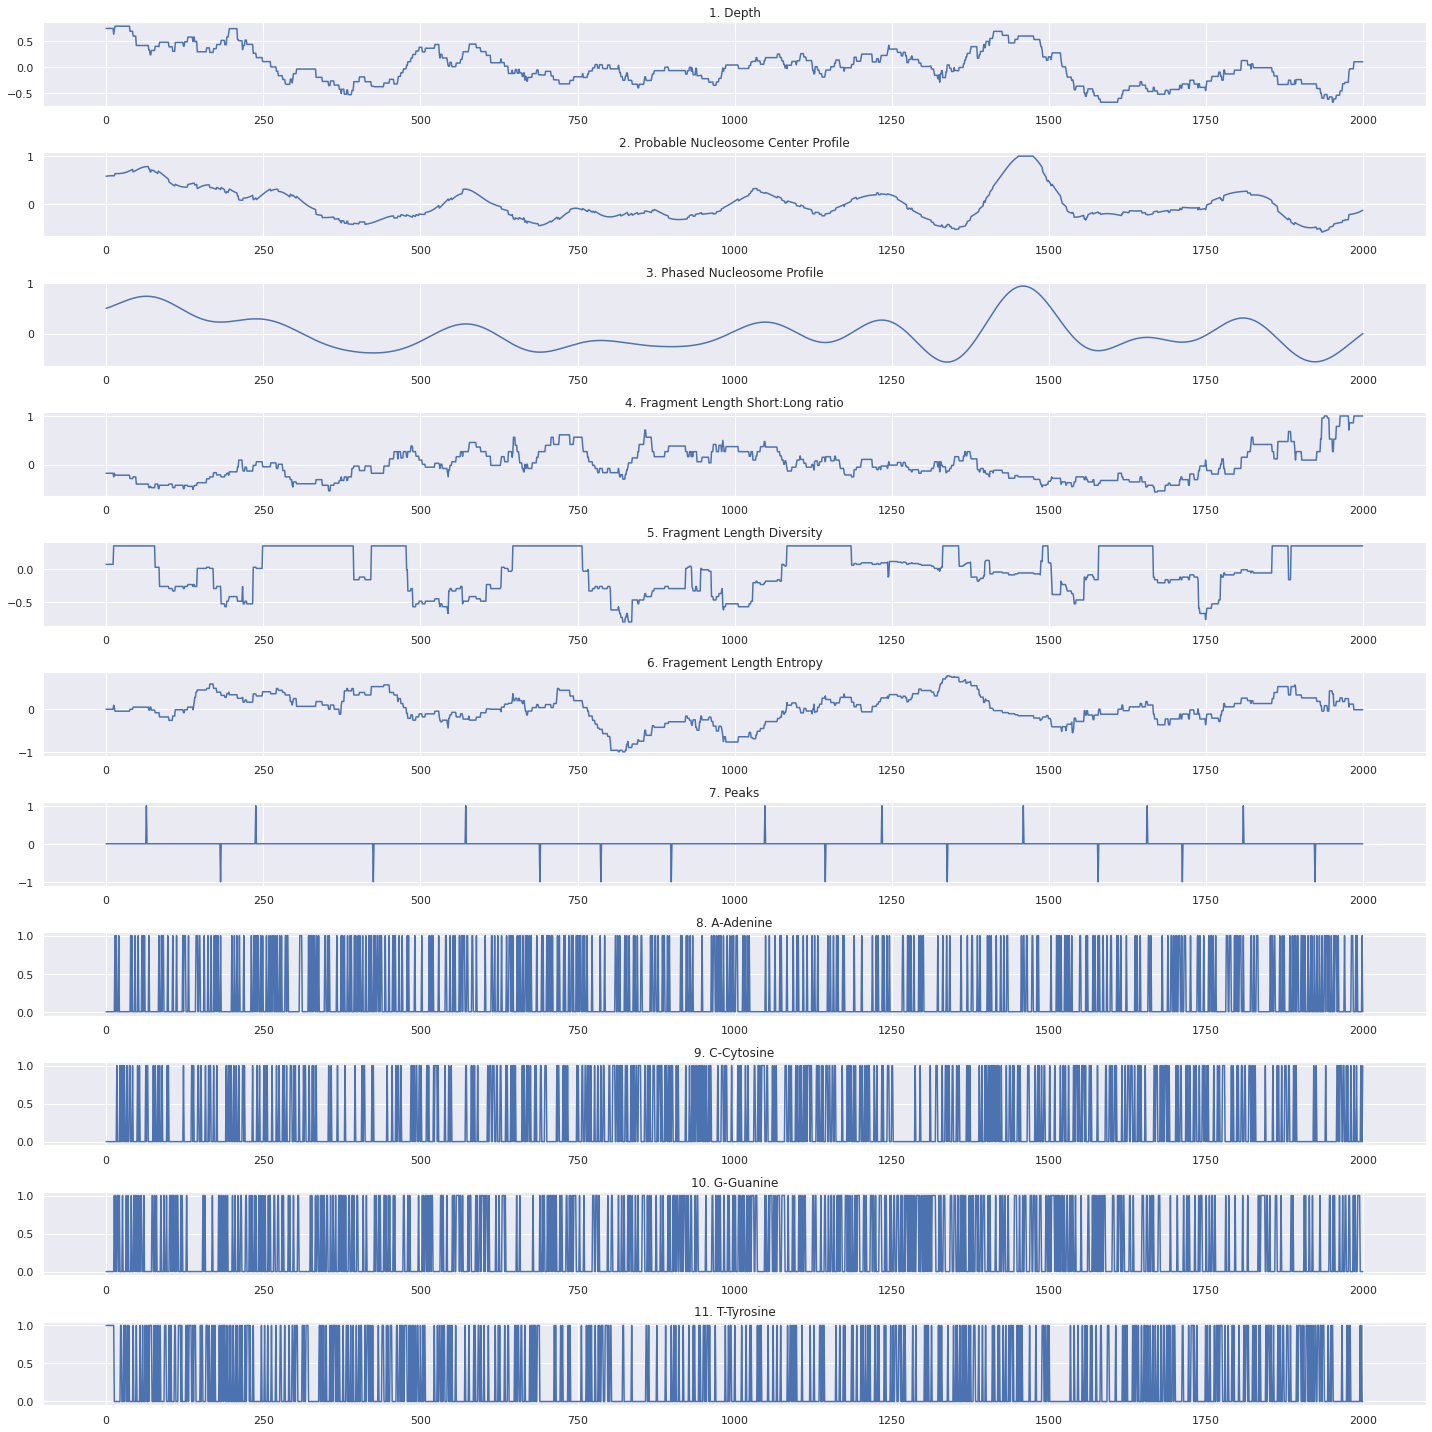

In [58]:
plot_images(i)

In [59]:
import pywt

In [71]:
i[:, :3].shape

(2000, 3)

In [60]:
cA, cD = pywt.dwt(i[:, 0], 'haar')

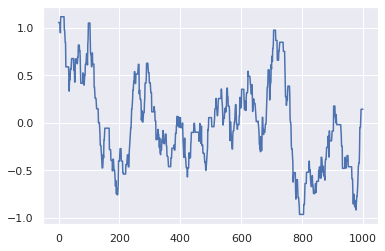

In [63]:
plt.plot(cA)

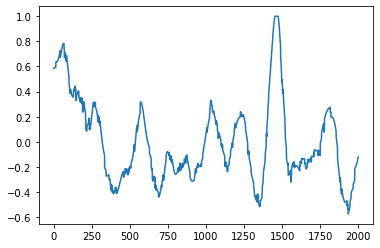

In [23]:
plt.plot(i[:, 1])

# Continuous label analysis

In [72]:
con_lbl_path = "/fh/scratch/delete90/ha_g/users/anair3/repositories/cfDNA-gene-exp-inference/data/labels/LuCaP_AvgL2FPKM.tsv"

In [73]:
import pandas as pd

In [75]:
data = pd.read_csv(con_lbl_path, sep='\t', index_col=0)
data.head()

,23-1,23-1CR,23-1CR3,35,35CR,49,58,70,70CR,73,...,189-3,189-3CR,189-4,208-1,208-2,208-4,235-2,235-3,235-3CR,243
A1BG,-6.286257,-5.853844,-3.710692,-0.773362,-1.592927,0.612145,-5.013024,1.522601,0.442940,-3.866903,...,-0.722429,-2.123497,-1.263390,0.133866,-0.122871,-0.457877,-2.182677,-2.294127,-1.286864,-2.633494
A2M,-5.747849,-4.268753,-5.750584,-5.841096,-7.439342,-6.572675,-5.901555,-10.417430,-6.065902,-7.384718,...,0.935721,-0.201570,-3.956641,-6.635300,-5.479160,-4.612896,-4.393496,-8.573650,-10.417430,-3.905463
A2MP1,-9.874888,-6.736063,-5.837311,-9.874888,-8.878341,-9.874888,-4.566472,-9.874888,-9.874888,-9.874888,...,-5.534803,-8.339376,-9.874888,-9.874888,-8.142851,-9.874888,-8.429070,-9.874888,-9.874888,-6.522993
NAT1,3.465605,2.497747,1.803760,2.169601,2.268883,0.547794,1.384505,1.905363,1.477696,-1.384812,...,2.494659,1.008395,2.974278,0.502789,0.273021,0.555642,1.025046,3.569957,1.343632,-0.486476
NAT2,-8.104738,-6.895608,-6.827246,-3.616872,-3.384497,-1.946024,-8.104738,-5.468731,-4.105587,-8.104738,...,-8.104738,-4.977509,-8.104738,-8.104738,-8.104738,-8.104738,-1.755334,-2.903413,-6.624177,-8.104738


In [76]:
data.to_csv("/fh/scratch/delete90/ha_g/users/anair3/repositories/cfDNA-gene-exp-inference/data/labels/labels_continuous_AvgL2fpkm.csv")

In [77]:
import numpy as np

In [80]:
c = np.load("/fh/scratch/delete90/ha_g/users/anair3/repositories/cfDNA-gene-exp-inference/data/continuous/testing.npz")

In [81]:
c["labels"]

array([-2.2303964 , -2.31143417,  1.82616042, ..., -7.0084067 ,
       -7.03259108, -4.66631909])